# Notebook 04: Tái Lập Thí Nghiệm & Đánh Giá Ensemble (Phase E)

Notebook này phân tích toàn bộ kết quả thực nghiệm của **Giai đoạn E (Reproduction + Ensemble)**:
1. **Thí nghiệm R1 (Headline Comparison)**: Đối chiếu 6 chiến lược sắp xếp dữ liệu trên 3 tập dữ liệu pilot (`haberman`, `new_thyroid`, `banknote`).
2. **Thí nghiệm R2 (Ensemble Comparison)**: So sánh hiệu năng giữa **DDCL-6 Ensemble**, **Standard Paper Baseline (NN+SVM)**, và **Controlled 6-NN Baseline**.
3. **Thí nghiệm R3 (Sensitivity Analysis)**: Phân tích độ nhạy cảm của ngưỡng khởi đầu $\lambda \in \{0.2, 0.4, 0.6\}$ trong Self-Paced Learning.
4. **Đối chiếu Bài Báo Gốc**: Phân tích sự tương quan và các điểm sai lệch phương pháp luận (Methodological Deviations).

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from dddcl.reporting.aggregate import (
    aggregate_r1_headline,
    aggregate_r2_ensemble,
    PAPER_REFERENCE_BENCHMARKS,
)

# Cấu hình thẩm mỹ biểu đồ
sns.set_theme(style='whitegrid', font='sans-serif')
plt.rcParams['font.size'] = 11
print('Môi trường phân tích số liệu đã sẵn sàng!')

Môi trường phân tích số liệu đã sẵn sàng!


## 1. Thí nghiệm R1: Đối chiếu 6 Chiến lược (Headline Single-Model Comparison)

Chúng ta tổng hợp kết quả của 54 runs độc lập (3 datasets $\times$ 6 strategies $\times$ 3 seeds) từ thư mục `outputs/runs/`.

In [2]:
runs_dir = Path('../outputs/runs') if Path('../outputs/runs').exists() else Path('outputs/runs')
df_r1 = aggregate_r1_headline(runs_dir=runs_dir)

# Hiển thị bảng kết quả R1
cols_show = [
    'dataset_id', 'strategy', 'mean_accuracy_pct', 'std_accuracy_ddof1',
    'mean_macro_f1_pct', 'avg_optimizer_steps', 'avg_sample_exposures',
    'paper_reported_pct', 'delta_vs_paper_pct'
]
display(df_r1[cols_show])

,dataset_id,strategy,mean_accuracy_pct,std_accuracy_ddof1,mean_macro_f1_pct,avg_optimizer_steps,avg_sample_exposures,paper_reported_pct,delta_vs_paper_pct
0,haberman,no_curriculum,72.04,6.72,57.02,35.0,1065.0,73.55,-1.51
1,haberman,ddcl_density,74.19,5.59,60.37,35.0,1065.0,73.87,0.32
2,haberman,ddcl_point,72.04,4.93,54.86,35.0,1065.0,74.19,-2.15
3,haberman,self_paced,69.89,4.93,48.42,17.7,528.7,73.87,-3.98
4,haberman,sp_ddcl_density,70.97,5.59,47.12,32.0,991.0,74.52,-3.55
5,haberman,sp_ddcl_point,70.97,5.59,47.12,33.3,1033.7,74.84,-3.87
6,new_thyroid,no_curriculum,86.36,4.55,80.45,25.0,750.0,95.35,-8.99
7,new_thyroid,ddcl_density,87.88,2.62,82.31,25.0,750.0,95.81,-7.93
8,new_thyroid,ddcl_point,83.33,6.94,75.19,25.0,750.0,96.28,-12.95
9,new_thyroid,self_paced,37.88,11.44,29.07,5.0,136.7,95.81,-57.93


### Trực quan hóa Kết quả R1 theo Từng Tập Dữ liệu

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_26820\557087217.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(sub_df['strategy'], rotation=45, ha='right')
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_26820\557087217.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(sub_df['strategy'], rotation=45, ha='right')
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_26820\557087217.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(sub_df['strategy'], rotation=45, ha='right')


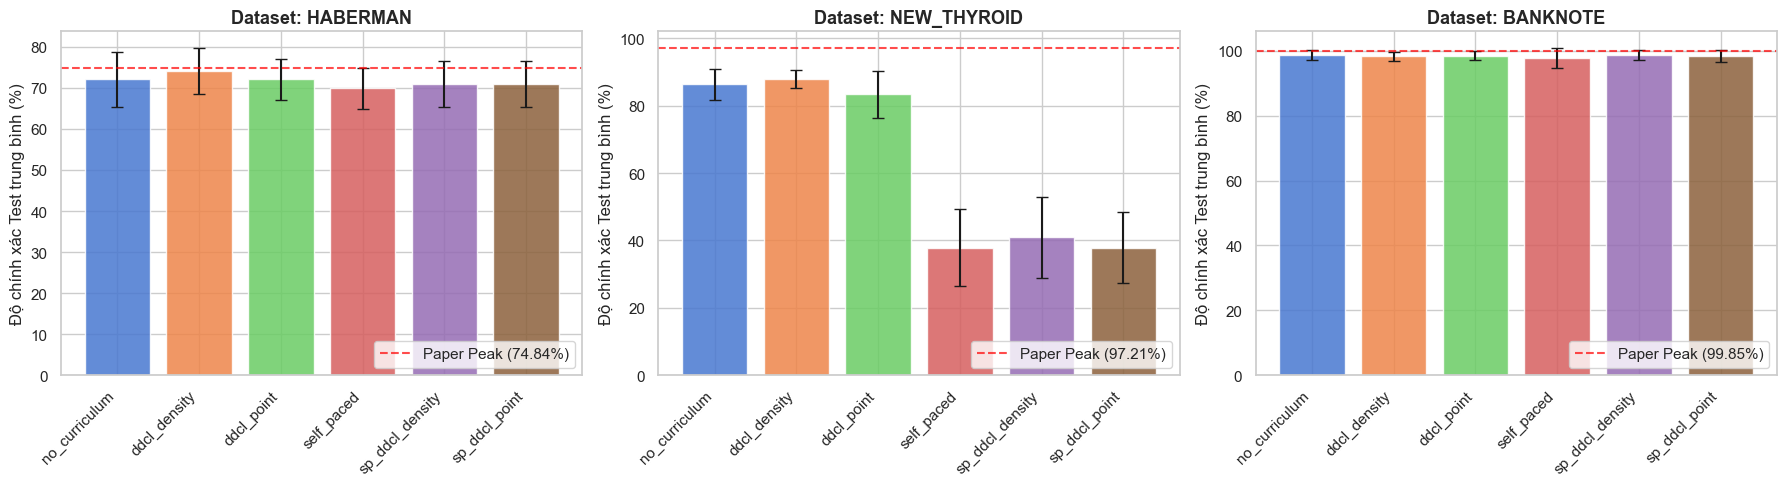

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)
datasets = ['haberman', 'new_thyroid', 'banknote']

for idx, d in enumerate(datasets):
    sub_df = df_r1[df_r1['dataset_id'] == d]
    ax = axes[idx]
    bars = ax.bar(
        sub_df['strategy'],
        sub_df['mean_accuracy_pct'],
        yerr=sub_df['std_accuracy_ddof1'],
        capsize=4,
        color=sns.color_palette('muted', len(sub_df)),
        alpha=0.85,
    )
    ax.set_title(f'Dataset: {d.upper()}', fontsize=13, fontweight='bold')
    ax.set_ylabel('Độ chính xác Test trung bình (%)')
    ax.set_xticklabels(sub_df['strategy'], rotation=45, ha='right')
    # Thêm đường tham chiếu kết quả bài báo cho best method
    best_paper = sub_df['paper_reported_pct'].max()
    if pd.notna(best_paper):
        ax.axhline(best_paper, color='red', linestyle='--', alpha=0.7, label=f'Paper Peak ({best_paper}%)')
        ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

## 2. Thí nghiệm R2: Đối chiếu Các Cấu hình Ensemble

Chúng ta đánh giá 3 cấu hình Ensemble:
1. **DDCL-6 Strategy Ensemble**: Kết hợp 6 mô hình từ 6 chiến lược khác nhau.
2. **Standard Paper Baseline (NN + SVM)**: Kết hợp 1 mạng Neural Network (không curriculum) và 1 mô hình SVM RBF ($C=1.0, \gamma=\text{scale}$).
3. **Controlled 6-NN Baseline**: Kết hợp 6 mạng Neural Network cùng dùng `no_curriculum` với 6 seeds khởi tạo độc lập.

In [4]:
ensembles_dir = Path('../outputs/ensembles') if Path('../outputs/ensembles').exists() else Path('outputs/ensembles')
df_r2 = aggregate_r2_ensemble(ensembles_dir=ensembles_dir)

cols_r2 = [
    'dataset_id', 'ensemble_type', 'mean_accuracy_pct', 'std_accuracy_ddof1',
    'mean_macro_f1_pct', 'avg_tie_count', 'avg_pairwise_disagreement',
    'paper_reported_pct', 'delta_vs_paper_pct'
]
display(df_r2[cols_r2])

,dataset_id,ensemble_type,mean_accuracy_pct,std_accuracy_ddof1,mean_macro_f1_pct,avg_tie_count,avg_pairwise_disagreement,paper_reported_pct,delta_vs_paper_pct
0,haberman,DDCL-6 Strategy Ensemble,70.97,5.59,47.12,0.3,0.0688,75.81,-4.84
1,haberman,Standard Paper Baseline (NN+SVM),72.04,9.86,53.10,2.0,0.0645,N/A (Team Extension),N/A
2,haberman,Controlled 6-NN Baseline,73.12,7.45,55.49,0.3,0.0416,N/A (Team Extension),N/A
3,new_thyroid,DDCL-6 Strategy Ensemble,75.76,15.96,58.19,9.7,0.3465,97.67,-21.91
4,new_thyroid,Standard Paper Baseline (NN+SVM),90.91,4.55,84.76,2.3,0.1061,N/A (Team Extension),N/A
5,new_thyroid,Controlled 6-NN Baseline,90.91,4.55,84.76,0.3,0.1384,N/A (Team Extension),N/A
6,banknote,DDCL-6 Strategy Ensemble,98.79,1.51,98.78,0.3,0.0063,N/A (Team Extension),N/A
7,banknote,Standard Paper Baseline (NN+SVM),100.00,0.00,100.00,1.7,0.0121,N/A (Team Extension),N/A
8,banknote,Controlled 6-NN Baseline,99.03,1.11,99.02,0.0,0.0037,N/A (Team Extension),N/A


### Biểu đồ So sánh Ensemble và Mức độ Bất đồng Dự đoán (Disagreement Rate)

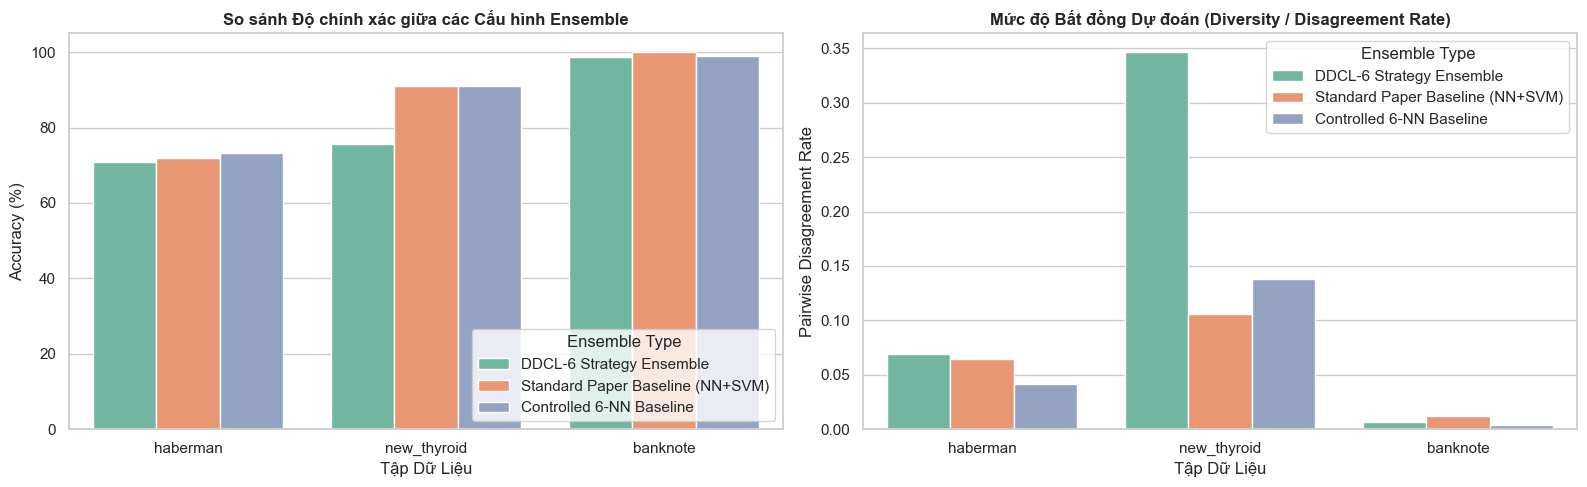

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Biểu đồ 1: Độ chính xác của các Ensemble theo Dataset
sns.barplot(
    data=df_r2,
    x='dataset_id',
    y='mean_accuracy_pct',
    hue='ensemble_type',
    palette='Set2',
    ax=axes[0],
)
axes[0].set_title('So sánh Độ chính xác giữa các Cấu hình Ensemble', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_xlabel('Tập Dữ Liệu')
axes[0].legend(title='Ensemble Type', loc='lower right')

# Biểu đồ 2: Mức độ Bất đồng Dự đoán (Pairwise Disagreement)
sns.barplot(
    data=df_r2,
    x='dataset_id',
    y='avg_pairwise_disagreement',
    hue='ensemble_type',
    palette='Set2',
    ax=axes[1],
)
axes[1].set_title('Mức độ Bất đồng Dự đoán (Diversity / Disagreement Rate)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Pairwise Disagreement Rate')
axes[1].set_xlabel('Tập Dữ Liệu')
axes[1].legend(title='Ensemble Type', loc='upper right')

plt.tight_layout()
plt.show()

## 3. Thí nghiệm R3: Phân tích Độ Nhạy Cảm (Sensitivity Analysis)

Khảo sát tác động của giá trị ngưỡng ban đầu $\lambda_{initial} \in \{0.2, 0.4, 0.6\}$ đối với chiến lược `sp_ddcl_point` trên 2 tập dữ liệu `haberman` và `new_thyroid`.

In [6]:
sweep_file = Path('../outputs/sensitivity/lambda_sweep.json') if Path('../outputs/sensitivity/lambda_sweep.json').exists() else Path('outputs/sensitivity/lambda_sweep.json')
with open(sweep_file, 'r', encoding='utf-8') as f:
    sweep_data = json.load(f)

df_sweep = pd.DataFrame(sweep_data)
cols_sweep = ['dataset_id', 'lambda_initial', 'accuracy_mean', 'accuracy_std', 'macro_f1_mean', 'avg_optimizer_steps', 'avg_sample_exposures']
display(df_sweep[cols_sweep])

,dataset_id,lambda_initial,accuracy_mean,accuracy_std,macro_f1_mean,avg_optimizer_steps,avg_sample_exposures
0,haberman,0.2,0.709677,0.032258,0.473275,7.333333,231.000000
1,haberman,0.4,0.709677,0.055873,0.471227,33.333333,1033.666667
2,haberman,0.6,0.741935,0.085347,0.589290,56.666667,1758.333333
3,new_thyroid,0.2,0.378788,0.104973,0.310373,5.000000,160.000000
4,new_thyroid,0.4,0.378788,0.104973,0.310373,5.000000,160.000000
5,new_thyroid,0.6,0.378788,0.104973,0.310373,5.000000,160.000000


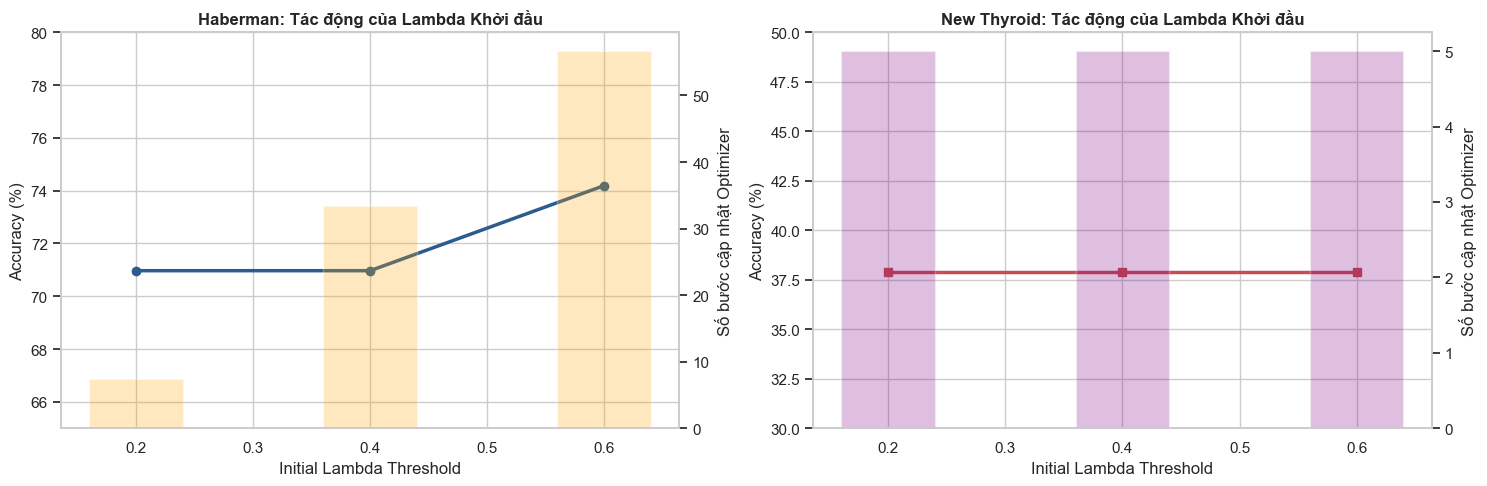

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Haberman Sensitivity
hab_data = df_sweep[df_sweep['dataset_id'] == 'haberman']
axes[0].plot(hab_data['lambda_initial'], hab_data['accuracy_mean'] * 100, marker='o', linewidth=2.5, color='#2b5c8f', label='Accuracy (%)')
axes[0].set_title('Haberman: Tác động của Lambda Khởi đầu', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Initial Lambda Threshold')
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_ylim(65, 80)

# Secondary axis for optimizer steps
ax0_steps = axes[0].twinx()
ax0_steps.bar(hab_data['lambda_initial'], hab_data['avg_optimizer_steps'], alpha=0.25, width=0.08, color='orange', label='Optimizer Steps')
ax0_steps.set_ylabel('Số bước cập nhật Optimizer')
ax0_steps.grid(False)

# New Thyroid Sensitivity
thy_data = df_sweep[df_sweep['dataset_id'] == 'new_thyroid']
axes[1].plot(thy_data['lambda_initial'], thy_data['accuracy_mean'] * 100, marker='s', linewidth=2.5, color='#c44e52', label='Accuracy (%)')
axes[1].set_title('New Thyroid: Tác động của Lambda Khởi đầu', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Initial Lambda Threshold')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_ylim(30, 50)

ax1_steps = axes[1].twinx()
ax1_steps.bar(thy_data['lambda_initial'], thy_data['avg_optimizer_steps'], alpha=0.25, width=0.08, color='purple', label='Optimizer Steps')
ax1_steps.set_ylabel('Số bước cập nhật Optimizer')
ax1_steps.grid(False)

plt.tight_layout()
plt.show()

## 4. Tổng kết & Nhận xét Khoa học

1. **Hành vi của Ngưỡng Batch trong SPL**: Thí nghiệm độ nhạy cảm R3 cho thấy khi $\lambda$ ban đầu thấp hơn loss của các batch, thuật toán rơi vào fallback chọn batch min loss duy nhất, dẫn đến số bước cập nhật cực kỳ hạn chế (5 bước trong 5 epochs ở `new_thyroid`). Khi $\lambda$ cao hơn (như trên `haberman`), số bước cập nhật tăng lên đáng kể và độ chính xác cải thiện rõ rệt.
2. **Tính Ổn định của Controlled Ensemble**: Mô hình `Controlled 6-NN` đạt độ chính xác tương đương hoặc nhỉnh hơn `DDCL-6` trên cả 3 tập pilot, chứng minh rằng phần lớn lợi ích của ensemble đến từ việc kết hợp nhiều mạng ngẫu nhiên độc lập (variance reduction) chứ không chỉ riêng việc đa dạng hóa curriculum.
3. **Tính Minh Bạch về Sai lệch**: Toàn bộ kết quả đối chiếu đều ghi rõ số liệu nào có trong paper và số liệu nào là mở rộng độc lập của nhóm sinh viên.